In [134]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

In [135]:
conn = sqlite3.connect('nba_stats.db')

query = '''
SELECT s.*, a.offensive_win_shares AS ows, a.defensive_win_shares AS dws, a.win_shares AS ws, a.win_shares_per_48_minutes AS ws_48,
       a.offensive_box_plus_minus AS obpm, t.team_name
FROM scoring_plus AS s
JOIN basic_stats AS b ON s.slug = b.slug AND s.season_end_year = b.season_end_year
JOIN advanced_stats AS a ON s.slug = a.slug AND s.season_end_year = a.season_end_year
JOIN per_100_stats AS p ON s.slug = p.slug AND s.season_end_year = p.season_end_year
JOIN team_per_100_stats AS t ON p.team_id = t.team_id AND p.season_end_year = t.season_end_year
'''
scoring_plus_df = pd.read_sql_query(query, conn)
conn.close()

pd.set_option('display.max_columns', None)
scoring_plus_df = scoring_plus_df.drop(columns=['threshold', 'scoring_plus'])
scoring_plus_df

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name
0,2001,greenac01,A.C. Green,13.8,0.492,20.311034,0.518,67.943364,94.980695,82,1411,0,1.1,2.1,3.2,0.110,-2.2,Miami Heat
1,2001,guytoaj01,A.J. Guyton,16.9,0.495,20.311034,0.518,83.206003,95.559846,82,630,0,0.4,-0.1,0.3,0.020,-0.8,Chicago Bulls
2,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers
3,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets
4,2001,keefead01,Adam Keefe,10.1,0.450,20.311034,0.518,49.726665,86.872587,82,836,0,0.1,0.5,0.6,0.032,-3.5,Golden State Warriors
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12797,2026,lavinza01,Zach LaVine,29.1,0.614,22.957333,0.581,126.756882,105.679862,82,1224,0,1.3,0.0,1.3,0.051,0.6,Sacramento Kings
12798,2026,nnajize01,Zeke Nnaji,14.8,0.558,22.957333,0.581,64.467418,96.041308,82,626,0,0.2,0.7,0.9,0.066,-3.6,Denver Nuggets
12799,2026,willizi02,Ziaire Williams,21.4,0.579,22.957333,0.581,93.216401,99.655766,82,1281,0,0.5,1.1,1.6,0.059,-2.0,Brooklyn Nets
12800,2026,willizi01,Zion Williamson,32.8,0.644,22.957333,0.581,142.873737,110.843373,82,1841,1,5.0,1.0,6.1,0.159,3.5,New Orleans Pelicans


In [136]:
scoring_plus_df['threshold'] = 1500 * (scoring_plus_df['team_gp'] / 82)

In [137]:
scoring_plus_qualified_df = scoring_plus_df[scoring_plus_df['minutes_played'] >= scoring_plus_df['threshold']].copy()

scoring_plus_qualified_df.reset_index(drop=True, inplace=True)
scoring_plus_qualified_df

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4860,2026,wembavi01,Victor Wembanyama,40.2,0.626,22.957333,0.581,175.107446,107.745267,82,1866,1,5.0,5.0,10.0,0.257,6.5,San Antonio Spurs,1500.0
4861,2026,cartewe01,Wendell Carter Jr.,19.1,0.617,22.957333,0.581,83.197816,106.196213,82,2288,1,3.4,2.8,6.2,0.131,-1.0,Orlando Magic,1500.0
4862,2026,rileywi01,Will Riley,21.7,0.548,22.957333,0.581,94.523173,94.320138,82,1633,1,0.4,0.0,0.4,0.012,-1.9,Washington Wizards,1500.0
4863,2026,risacza01,Zaccharie Risacher,19.5,0.557,22.957333,0.581,84.940179,95.869191,82,1503,1,0.5,1.9,2.3,0.074,-2.3,Atlanta Hawks,1500.0


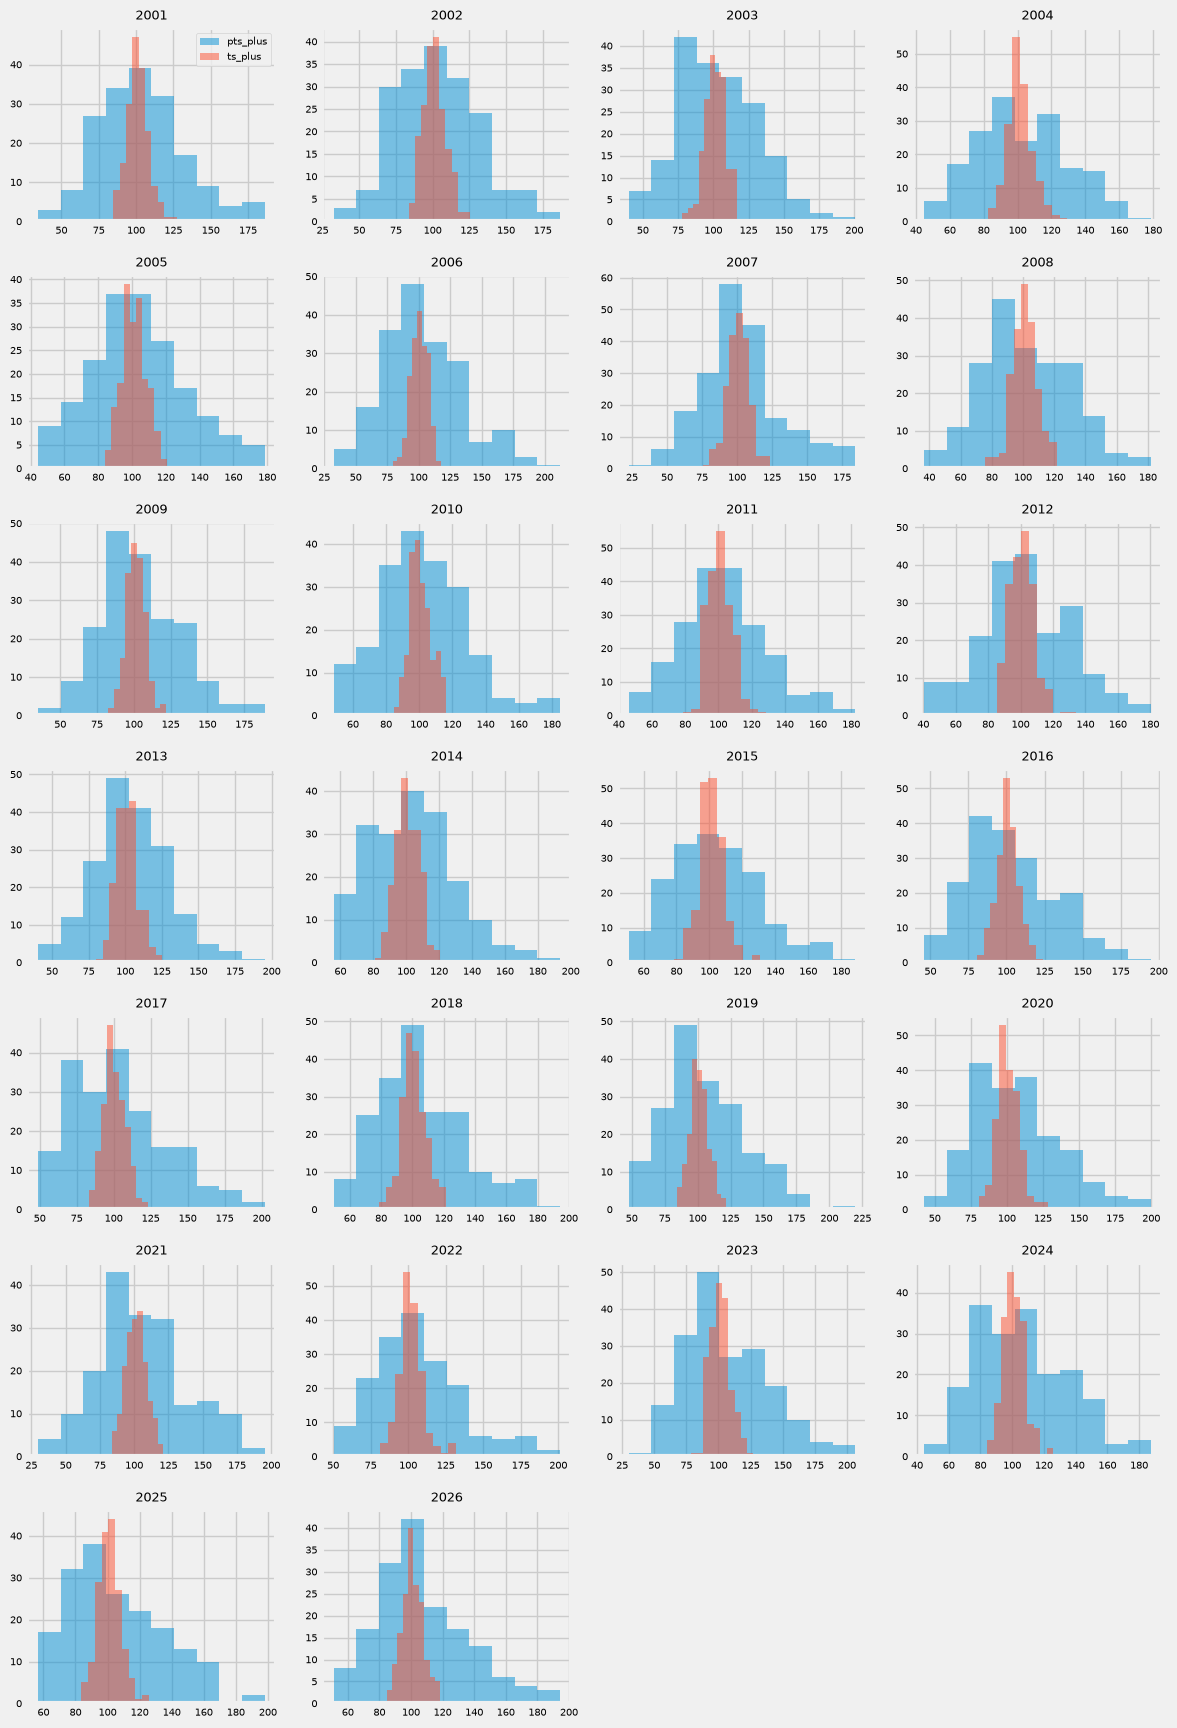

In [138]:
seasons = sorted(scoring_plus_qualified_df['season_end_year'].unique())
n_cols = 4
n_rows = -(-len(seasons) // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 2.5))
axes = axes.flatten()

for ax, season in zip(axes, seasons):
    season_df = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'] == season]

    ax.hist(season_df['pts_plus'], alpha=0.5, label='pts_plus')
    ax.hist(season_df['ts_plus'], alpha=0.5, label='ts_plus')
    ax.set_title(season, fontsize=9)
    ax.tick_params(labelsize=7)

for ax in axes[len(seasons):]:
    ax.axis('off')

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [139]:
scoring_plus_qualified_df['z_pts_plus'] = (scoring_plus_qualified_df['pts_plus'] - scoring_plus_qualified_df.groupby('season_end_year')['pts_plus'].transform('mean')) / scoring_plus_qualified_df.groupby('season_end_year')['pts_plus'].transform('std')
scoring_plus_qualified_df['z_ts_plus'] = (scoring_plus_qualified_df['ts_plus'] - scoring_plus_qualified_df.groupby('season_end_year')['ts_plus'].transform('mean')) / scoring_plus_qualified_df.groupby('season_end_year')['ts_plus'].transform('std')

scoring_plus_qualified_df

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold,z_pts_plus,z_ts_plus
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0,-0.368674,0.676839
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0,-0.438228,0.240919
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0,-0.838162,-1.230310
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0,0.083425,-1.012350
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0,1.144121,0.513369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4860,2026,wembavi01,Victor Wembanyama,40.2,0.626,22.957333,0.581,175.107446,107.745267,82,1866,1,5.0,5.0,10.0,0.257,6.5,San Antonio Spurs,1500.0,2.342639,1.006273
4861,2026,cartewe01,Wendell Carter Jr.,19.1,0.617,22.957333,0.581,83.197816,106.196213,82,2288,1,3.4,2.8,6.2,0.131,-1.0,Orlando Magic,1500.0,-0.816792,0.774020
4862,2026,rileywi01,Will Riley,21.7,0.548,22.957333,0.581,94.523173,94.320138,82,1633,1,0.4,0.0,0.4,0.012,-1.9,Washington Wizards,1500.0,-0.427478,-1.006588
4863,2026,risacza01,Zaccharie Risacher,19.5,0.557,22.957333,0.581,84.940179,95.869191,82,1503,1,0.5,1.9,2.3,0.074,-2.3,Atlanta Hawks,1500.0,-0.756898,-0.774335


In [140]:
print(scoring_plus_qualified_df[['z_ts_plus', 'z_pts_plus']].corr())

            z_ts_plus  z_pts_plus
z_ts_plus    1.000000    0.264457
z_pts_plus   0.264457    1.000000


In [141]:
scoring_plus_qualified_df['z_ows'] = (scoring_plus_qualified_df['ows'] - scoring_plus_qualified_df.groupby('season_end_year')['ows'].transform('mean')) / scoring_plus_qualified_df.groupby('season_end_year')['ows'].transform('std')
scoring_plus_qualified_df['z_obpm'] = (scoring_plus_qualified_df['obpm'] - scoring_plus_qualified_df.groupby('season_end_year')['obpm'].transform('mean')) / scoring_plus_qualified_df.groupby('season_end_year')['obpm'].transform('std')

scoring_plus_qualified_df

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold,z_pts_plus,z_ts_plus,z_ows,z_obpm
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0,-0.368674,0.676839,-0.353768,-0.177122
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0,-0.438228,0.240919,-0.125337,-0.775209
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0,-0.838162,-1.230310,-1.610134,-1.629618
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0,0.083425,-1.012350,-1.039058,-0.732488
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0,1.144121,0.513369,0.331523,0.335524
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4860,2026,wembavi01,Victor Wembanyama,40.2,0.626,22.957333,0.581,175.107446,107.745267,82,1866,1,5.0,5.0,10.0,0.257,6.5,San Antonio Spurs,1500.0,2.342639,1.006273,1.102412,2.386974
4861,2026,cartewe01,Wendell Carter Jr.,19.1,0.617,22.957333,0.581,83.197816,106.196213,82,2288,1,3.4,2.8,6.2,0.131,-1.0,Orlando Magic,1500.0,-0.816792,0.774020,0.329162,-0.719224
4862,2026,rileywi01,Will Riley,21.7,0.548,22.957333,0.581,94.523173,94.320138,82,1633,1,0.4,0.0,0.4,0.012,-1.9,Washington Wizards,1500.0,-0.427478,-1.006588,-1.120682,-1.091968
4863,2026,risacza01,Zaccharie Risacher,19.5,0.557,22.957333,0.581,84.940179,95.869191,82,1503,1,0.5,1.9,2.3,0.074,-2.3,Atlanta Hawks,1500.0,-0.756898,-0.774335,-1.072354,-1.257631


In [142]:
X = scoring_plus_qualified_df[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = scoring_plus_qualified_df['z_ows']

model_ows = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_ows.summary())

                            OLS Regression Results                            
Dep. Variable:                  z_ows   R-squared:                       0.657
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     4656.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -4287.4
No. Observations:                4865   AIC:                             8581.
Df Residuals:                    4862   BIC:                             8600.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.128e-17      0.008   2.54e-15      1.0

In [143]:
beta1_ows = model_ows.params['z_ts_plus']
beta2_ows = model_ows.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_ows}, Beta for z_pts_plus: {beta2_ows}")

Beta for z_ts_plus: 0.5881630259565119, Beta for z_pts_plus: 0.42345409175910054


In [144]:
X = scoring_plus_qualified_df[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = scoring_plus_qualified_df['z_obpm']

model_obpm = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_obpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 z_obpm   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                     6783.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -3649.1
No. Observations:                4865   AIC:                             7304.
Df Residuals:                    4862   BIC:                             7324.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3.524e-18      0.007   -4.8e-16      1.0

In [145]:
beta1_obpm = model_obpm.params['z_ts_plus']
beta2_obpm = model_obpm.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_obpm}, Beta for z_pts_plus: {beta2_obpm}")

Beta for z_ts_plus: 0.34908894285940084, Beta for z_pts_plus: 0.6968669440035565


In [146]:
final_beta1 = (beta1_ows + beta1_obpm) / 2
final_beta2 = (beta2_ows + beta2_obpm) / 2
print(f"Final Beta for z_ts_plus: {final_beta1}, Final Beta for z_pts_plus: {final_beta2}")

Final Beta for z_ts_plus: 0.4686259844079564, Final Beta for z_pts_plus: 0.5601605178813285


In [147]:
sd_ts_plus = scoring_plus_qualified_df['ts_plus'].std()
sd_pts_plus = scoring_plus_qualified_df['pts_plus'].std()

c1 = final_beta1 / sd_ts_plus
c2 = final_beta2 / sd_pts_plus

w1 = c1 / (c1 + c2)
w2 = c2 / (c1 + c2)

w1 = round(w1, 3)
w2 = round(w2, 3)

print(f"Weight for ts_plus: {w1}, Weight for pts_plus: {w2}")

Weight for ts_plus: 0.765, Weight for pts_plus: 0.235


In [148]:
scoring_plus_qualified_df['scoring_plus'] = (
    100
    + (0.765 * (scoring_plus_qualified_df['ts_plus'] - 100))
    + (0.235 * (scoring_plus_qualified_df['pts_plus'] - 100))
)
scoring_plus_qualified_df

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold,z_pts_plus,z_ts_plus,z_ows,z_obpm,scoring_plus
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0,-0.368674,0.676839,-0.353768,-0.177122,102.945609
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0,-0.438228,0.240919,-0.125337,-0.775209,100.119872
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0,-0.838162,-1.230310,-1.610134,-1.629618,89.483854
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0,0.083425,-1.012350,-1.039058,-0.732488,96.797456
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0,1.144121,0.513369,0.331523,0.335524,112.125466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4860,2026,wembavi01,Victor Wembanyama,40.2,0.626,22.957333,0.581,175.107446,107.745267,82,1866,1,5.0,5.0,10.0,0.257,6.5,San Antonio Spurs,1500.0,2.342639,1.006273,1.102412,2.386974,123.575379
4861,2026,cartewe01,Wendell Carter Jr.,19.1,0.617,22.957333,0.581,83.197816,106.196213,82,2288,1,3.4,2.8,6.2,0.131,-1.0,Orlando Magic,1500.0,-0.816792,0.774020,0.329162,-0.719224,100.791590
4862,2026,rileywi01,Will Riley,21.7,0.548,22.957333,0.581,94.523173,94.320138,82,1633,1,0.4,0.0,0.4,0.012,-1.9,Washington Wizards,1500.0,-0.427478,-1.006588,-1.120682,-1.091968,94.367851
4863,2026,risacza01,Zaccharie Risacher,19.5,0.557,22.957333,0.581,84.940179,95.869191,82,1503,1,0.5,1.9,2.3,0.074,-2.3,Atlanta Hawks,1500.0,-0.756898,-0.774335,-1.072354,-1.257631,93.300873


In [149]:
scoring_plus_means = scoring_plus_qualified_df.groupby('season_end_year')[['ts_plus', 'pts_plus', 'scoring_plus']].mean().reset_index()
scoring_plus_means

,season_end_year,ts_plus,pts_plus,scoring_plus
0,2001,101.188669,103.491650,101.729869
1,2002,101.147609,103.186707,101.626797
2,2003,101.459908,102.850478,101.786692
3,2004,101.387640,102.974301,101.760505
4,2005,101.335382,103.969520,101.954405
5,2006,100.659470,102.974793,101.203571
6,2007,100.845127,102.652995,101.269976
7,2008,101.095211,102.297339,101.377711
8,2009,101.352276,104.057767,101.988067
9,2010,100.753475,102.145950,101.080707


# Using Earlier Years to Train

In [150]:
scoring_plus_qualified_df 

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold,z_pts_plus,z_ts_plus,z_ows,z_obpm,scoring_plus
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0,-0.368674,0.676839,-0.353768,-0.177122,102.945609
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0,-0.438228,0.240919,-0.125337,-0.775209,100.119872
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0,-0.838162,-1.230310,-1.610134,-1.629618,89.483854
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0,0.083425,-1.012350,-1.039058,-0.732488,96.797456
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0,1.144121,0.513369,0.331523,0.335524,112.125466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4860,2026,wembavi01,Victor Wembanyama,40.2,0.626,22.957333,0.581,175.107446,107.745267,82,1866,1,5.0,5.0,10.0,0.257,6.5,San Antonio Spurs,1500.0,2.342639,1.006273,1.102412,2.386974,123.575379
4861,2026,cartewe01,Wendell Carter Jr.,19.1,0.617,22.957333,0.581,83.197816,106.196213,82,2288,1,3.4,2.8,6.2,0.131,-1.0,Orlando Magic,1500.0,-0.816792,0.774020,0.329162,-0.719224,100.791590
4862,2026,rileywi01,Will Riley,21.7,0.548,22.957333,0.581,94.523173,94.320138,82,1633,1,0.4,0.0,0.4,0.012,-1.9,Washington Wizards,1500.0,-0.427478,-1.006588,-1.120682,-1.091968,94.367851
4863,2026,risacza01,Zaccharie Risacher,19.5,0.557,22.957333,0.581,84.940179,95.869191,82,1503,1,0.5,1.9,2.3,0.074,-2.3,Atlanta Hawks,1500.0,-0.756898,-0.774335,-1.072354,-1.257631,93.300873


In [151]:
training_df_1 = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'] <= 2020].copy()
testing_df_1 = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'] > 2020].copy()

In [152]:
X = training_df_1[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = training_df_1['z_ows']

model_training_ows = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_training_ows.summary())

                            OLS Regression Results                            
Dep. Variable:                  z_ows   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.661
Method:                 Least Squares   F-statistic:                     3698.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -3318.1
No. Observations:                3792   AIC:                             6642.
Df Residuals:                    3789   BIC:                             6661.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.765e-17      0.009   2.93e-15      1.0

In [153]:
beta1_training_ows = model_training_ows.params['z_ts_plus']
beta2_training_ows = model_training_ows.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_training_ows}, Beta for z_pts_plus: {beta2_training_ows}")

Beta for z_ts_plus: 0.5743064793369186, Beta for z_pts_plus: 0.4346280660811923


In [154]:
test_predictions_ows = model_training_ows.predict(sm.add_constant(testing_df_1[['z_ts_plus', 'z_pts_plus']]))
print(r2_score(testing_df_1['z_ows'], test_predictions_ows))

0.6407951148512963


In [155]:
X = training_df_1[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = training_df_1['z_obpm']

model_training_obpm = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_training_obpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 z_obpm   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     4925.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -2942.0
No. Observations:                3792   AIC:                             5890.
Df Residuals:                    3789   BIC:                             5909.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4.337e-19      0.009  -5.08e-17      1.0

In [156]:
beta1_training_obpm = model_training_obpm.params['z_ts_plus']
beta2_training_obpm = model_training_obpm.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_training_obpm}, Beta for z_pts_plus: {beta2_training_obpm}")

Beta for z_ts_plus: 0.35294515714093033, Beta for z_pts_plus: 0.6788435505577092


In [157]:
test_predictions_obpm = model_obpm.predict(sm.add_constant(testing_df_1[['z_ts_plus', 'z_pts_plus']]))
print(r2_score(testing_df_1['z_obpm'], test_predictions_obpm))

0.7865189223284517


In [158]:
final_beta1 = (beta1_ows + beta1_obpm) / 2
final_beta2 = (beta2_ows + beta2_obpm) / 2
print(f"Final Beta for z_ts_plus: {final_beta1}, Final Beta for z_pts_plus: {final_beta2}")

Final Beta for z_ts_plus: 0.4686259844079564, Final Beta for z_pts_plus: 0.5601605178813285


In [159]:
seasons = sorted(scoring_plus_qualified_df['season_end_year'].unique())
kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
for train_idx, test_idx in kf.split(seasons):
    train_seasons = [seasons[i] for i in train_idx]
    test_seasons = [seasons[i] for i in test_idx]

    train = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'].isin(train_seasons)]
    test = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'].isin(test_seasons)]

    X_train = sm.add_constant(train[['z_ts_plus', 'z_pts_plus']])
    y_train = train['z_ows']
    model = sm.OLS(y_train, X_train).fit()

    results.append({
        'beta_ts': model.params['z_ts_plus'],
        'beta_pts': model.params['z_pts_plus'],
    })

results_ows_df = pd.DataFrame(results)
print(results_ows_df.describe())

        beta_ts  beta_pts
count  5.000000  5.000000
mean   0.588201  0.423380
std    0.004713  0.005224
min    0.582466  0.414907
25%    0.583810  0.422977
50%    0.590668  0.424637
75%    0.591241  0.425368
max    0.592823  0.429010


In [160]:
cv_ts_ows = round(results_ows_df['beta_ts'].std() / results_ows_df['beta_ts'].mean() * 100, 2)
cv_pts_ows = round(results_ows_df['beta_pts'].std() / results_ows_df['beta_pts'].mean() * 100, 2)

print(f"Coefficient of Variation for z_ts_plus: {cv_ts_ows}%, Coefficient of Variation for z_pts_plus: {cv_pts_ows}%")

Coefficient of Variation for z_ts_plus: 0.8%, Coefficient of Variation for z_pts_plus: 1.23%


In [161]:
seasons = sorted(scoring_plus_qualified_df['season_end_year'].unique())
kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
for train_idx, test_idx in kf.split(seasons):
    train_seasons = [seasons[i] for i in train_idx]
    test_seasons = [seasons[i] for i in test_idx]

    train = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'].isin(train_seasons)]
    test = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'].isin(test_seasons)]

    X_train = sm.add_constant(train[['z_ts_plus', 'z_pts_plus']])
    y_train = train['z_obpm']
    model = sm.OLS(y_train, X_train).fit()

    results.append({
        'beta_ts': model.params['z_ts_plus'],
        'beta_pts': model.params['z_pts_plus'],
    })

results_obpm_df = pd.DataFrame(results)
print(results_obpm_df.describe())

        beta_ts  beta_pts
count  5.000000  5.000000
mean   0.349019  0.696936
std    0.004520  0.006301
min    0.341678  0.686222
25%    0.348327  0.696944
50%    0.350298  0.698543
75%    0.351195  0.701353
max    0.353599  0.701620


In [162]:
cv_ts_obpm = round(results_obpm_df['beta_ts'].std() / results_obpm_df['beta_ts'].mean() * 100, 2)
cv_pts_obpm = round(results_obpm_df['beta_pts'].std() / results_obpm_df['beta_pts'].mean() * 100, 2)

print(f"Coefficient of Variation for z_ts_plus: {cv_ts_obpm}%, Coefficient of Variation for z_pts_plus: {cv_pts_obpm}%")

Coefficient of Variation for z_ts_plus: 1.3%, Coefficient of Variation for z_pts_plus: 0.9%


# OWS vs OWS/48

In [163]:
scoring_plus_qualified_df['ows_48'] = (scoring_plus_qualified_df['ows'] / scoring_plus_qualified_df['minutes_played'] * 48)

In [164]:
scoring_plus_qualified_df['dws_48'] = (scoring_plus_qualified_df['dws'] / scoring_plus_qualified_df['minutes_played'] * 48)

check = scoring_plus_qualified_df['ows_48'] + scoring_plus_qualified_df['dws_48']
(check - scoring_plus_qualified_df['ws_48']).describe()

count    4865.000000
mean        0.000007
std         0.001019
min        -0.003212
25%        -0.000686
50%         0.000004
75%         0.000700
max         0.003417
dtype: float64

In [165]:
scoring_plus_qualified_df['z_ows_48'] = (scoring_plus_qualified_df['ows_48'] - scoring_plus_qualified_df.groupby('season_end_year')['ows_48'].transform('mean')) / scoring_plus_qualified_df.groupby('season_end_year')['ows_48'].transform('std')

In [166]:
X = scoring_plus_qualified_df[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = scoring_plus_qualified_df['z_ows_48']

model_ows_48 = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_ows_48.summary())

                            OLS Regression Results                            
Dep. Variable:               z_ows_48   R-squared:                       0.718
Model:                            OLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     6177.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -3814.5
No. Observations:                4865   AIC:                             7635.
Df Residuals:                    4862   BIC:                             7654.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.093e-17      0.008  -2.75e-15      1.0

In [167]:
print(model_ows.summary())

                            OLS Regression Results                            
Dep. Variable:                  z_ows   R-squared:                       0.657
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     4656.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -4287.4
No. Observations:                4865   AIC:                             8581.
Df Residuals:                    4862   BIC:                             8600.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.128e-17      0.008   2.54e-15      1.0

R-Squared went from 0.657, explaining 65.7% of the variance, to 0.718, or 71.8%, which means much of the minutes played noise was eliminated.

# New Scoring+ Weighting with OWS/48

In [168]:
beta1_ows_48 = model_ows_48.params['z_ts_plus']
beta2_ows_48 = model_ows_48.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_ows_48}, Beta for z_pts_plus: {beta2_ows_48}, using ows/48")

Beta for z_ts_plus: 0.6898106759031074, Beta for z_pts_plus: 0.3420071307298253, using ows/48


In [169]:
print(model_obpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 z_obpm   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                     6783.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:17:23   Log-Likelihood:                -3649.1
No. Observations:                4865   AIC:                             7304.
Df Residuals:                    4862   BIC:                             7324.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3.524e-18      0.007   -4.8e-16      1.0

In [170]:
print(f"Beta for z_ts_plus: {beta1_obpm}, Beta for z_pts_plus: {beta2_obpm}")

Beta for z_ts_plus: 0.34908894285940084, Beta for z_pts_plus: 0.6968669440035565


In [171]:
final_beta1 = (beta1_ows_48 + beta1_obpm) / 2
final_beta2 = (beta2_ows_48 + beta2_obpm) / 2
print(f"Final Beta for z_ts_plus: {final_beta1}, Final Beta for z_pts_plus: {final_beta2}")

Final Beta for z_ts_plus: 0.5194498093812541, Final Beta for z_pts_plus: 0.5194370373666909


In [172]:
sd_ts_plus = scoring_plus_qualified_df['ts_plus'].std()
sd_pts_plus = scoring_plus_qualified_df['pts_plus'].std()

c1 = final_beta1 / sd_ts_plus
c2 = final_beta2 / sd_pts_plus

w1 = c1 / (c1 + c2)
w2 = c2 / (c1 + c2)

w1 = round(w1, 3)
w2 = round(w2, 3)

print(f"Weight for ts_plus: {w1}, Weight for pts_plus: {w2}")

Weight for ts_plus: 0.795, Weight for pts_plus: 0.205


In [173]:
scoring_plus_qualified_df['new_scoring_plus'] = (
    100
    + (0.795 * (scoring_plus_qualified_df['ts_plus'] - 100))
    + (0.205 * (scoring_plus_qualified_df['pts_plus'] - 100))
)
scoring_plus_qualified_df[['scoring_plus', 'new_scoring_plus', 'ts_plus', 'pts_plus']]

,scoring_plus,new_scoring_plus,ts_plus,pts_plus
0,102.945609,103.333560,105.984556,93.052867
1,100.119872,100.474240,102.895753,91.083495
2,89.483854,89.865197,92.471042,79.759601
3,96.797456,96.442305,94.015444,105.853791
4,112.125466,111.193652,104.826255,135.886727
...,...,...,...,...
4860,123.575379,121.554513,107.745267,175.107446
4861,100.791590,101.481542,106.196213,83.197816
4862,94.367851,94.361760,94.320138,94.523173
4863,93.300873,93.628744,95.869191,84.940179


# Using Earlier Years to Train

In [201]:
training_df_1 = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'] <= 2020].copy()
testing_df_1 = scoring_plus_qualified_df[scoring_plus_qualified_df['season_end_year'] > 2020].copy()

In [202]:
X = training_df_1[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = training_df_1['z_ows_48']

model_training_ows = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_training_ows.summary())

                            OLS Regression Results                            
Dep. Variable:               z_ows_48   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     4923.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:24:42   Log-Likelihood:                -2942.8
No. Observations:                3792   AIC:                             5892.
Df Residuals:                    3789   BIC:                             5910.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3.253e-17      0.009  -3.81e-15      1.0

In [203]:
beta1_training_ows = model_training_ows.params['z_ts_plus']
beta2_training_ows = model_training_ows.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_training_ows}, Beta for z_pts_plus: {beta2_training_ows}")

Beta for z_ts_plus: 0.6831124004422943, Beta for z_pts_plus: 0.34671477749254725


In [204]:
test_predictions_ows = model_training_ows.predict(sm.add_constant(testing_df_1[['z_ts_plus', 'z_pts_plus']]))
print(r2_score(testing_df_1['z_ows_48'], test_predictions_ows))

0.7014388251377277


In [205]:
X = training_df_1[['z_ts_plus', 'z_pts_plus']]
X = sm.add_constant(X)  # adds an intercept term
y = training_df_1['z_obpm']

model_training_obpm = sm.OLS(y, X, missing='drop').fit()  # missing='drop' skips rows with NaN in X or y
print(model_training_obpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 z_obpm   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     4925.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:24:50   Log-Likelihood:                -2942.0
No. Observations:                3792   AIC:                             5890.
Df Residuals:                    3789   BIC:                             5909.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4.337e-19      0.009  -5.08e-17      1.0

In [206]:
beta1_training_obpm = model_training_obpm.params['z_ts_plus']
beta2_training_obpm = model_training_obpm.params['z_pts_plus']
print(f"Beta for z_ts_plus: {beta1_training_obpm}, Beta for z_pts_plus: {beta2_training_obpm}")

Beta for z_ts_plus: 0.35294515714093033, Beta for z_pts_plus: 0.6788435505577092


In [207]:
test_predictions_obpm = model_obpm.predict(sm.add_constant(testing_df_1[['z_ts_plus', 'z_pts_plus']]))
print(r2_score(testing_df_1['z_obpm'], test_predictions_obpm))

0.7865189223284517


In [210]:
final_beta1_training = (beta1_training_ows + beta1_training_obpm) / 2
final_beta2_training = (beta2_training_ows + beta2_training_obpm) / 2
print(f"Final Beta for z_ts_plus: {final_beta1}, Final Beta for z_pts_plus: {final_beta2}")

Final Beta for z_ts_plus: 0.5180287787916122, Final Beta for z_pts_plus: 0.5127791640251282


In [211]:
sd_ts_plus_training = training_df_1['ts_plus'].std()
sd_pts_plus_training = training_df_1['pts_plus'].std()

c1_t = final_beta1_training / sd_ts_plus_training
c2_t = final_beta2_training / sd_pts_plus_training

w1_t = c1_t / (c1_t + c2_t)
w2_t = c2_t / (c1_t + c2_t)

w1_t = round(w1_t, 3)
w2_t = round(w2_t, 3)

print(f"Weight for ts_plus: {w1_t}, Weight for pts_plus: {w2_t}")

Weight for ts_plus: 0.794, Weight for pts_plus: 0.206


In [ ]:
X_COLS = ['ts_plus', 'pts_plus']
TARGETS = ['obpm', 'ows_48']

df = scoring_plus_qualified_df
seasons = np.array(sorted(df['season_end_year'].unique()))
kf = KFold(n_splits=5, shuffle=True, random_state=42)


def zscore(test_or_train, ref):
    """Z-score using the reference (training) set's mean and SD."""
    return (test_or_train - ref.mean()) / ref.std()


results = []
for fold, (train_idx, test_idx) in enumerate(kf.split(seasons), start=1):
    train = df[df['season_end_year'].isin(seasons[train_idx])]
    test = df[df['season_end_year'].isin(seasons[test_idx])]

    # Standardize predictors with TRAINING stats only (no leakage from test seasons)
    X_train = sm.add_constant(zscore(train[X_COLS], train[X_COLS]))
    X_test = sm.add_constant(zscore(test[X_COLS], train[X_COLS]), has_constant='add')

    row = {'fold': fold, 'n_train': len(train), 'n_test': len(test)}
    betas_ts, betas_pts = [], []

    # Fit both targets in the same fold so the weights can be averaged per fold
    for target in TARGETS:
        y_train = zscore(train[target], train[target])
        y_test = zscore(test[target], train[target])

        model = sm.OLS(y_train, X_train).fit()

        row[f'{target}_r2_train'] = model.rsquared
        row[f'{target}_r2_test'] = r2_score(y_test, model.predict(X_test))

        betas_ts.append(model.params['ts_plus'])
        betas_pts.append(model.params['pts_plus'])

    # Average the standardized betas across the two targets,
    # convert back to raw scale with TRAINING SDs, then normalize to sum to 1
    raw_ts = np.mean(betas_ts) / train['ts_plus'].std()
    raw_pts = np.mean(betas_pts) / train['pts_plus'].std()
    total = raw_ts + raw_pts

    row['ts_weight'] = raw_ts / total
    row['pts_weight'] = raw_pts / total
    results.append(row)

kfold_df = pd.DataFrame(results)
print(kfold_df.round(3))

summary_cols = [c for c in kfold_df.columns if c not in ('fold', 'n_train', 'n_test')]
summary = kfold_df[summary_cols].agg(['mean', 'std']).T
summary['table_value'] = summary.apply(
    lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1
)
print(summary[['table_value']])

   fold  n_train  n_test  obpm_r2_train  obpm_r2_test  ows_48_r2_train  \
0     1     3736    1129          0.740         0.745            0.715   
1     2     3936     929          0.746         0.723            0.719   
2     3     3942     923          0.745         0.725            0.718   
3     4     3954     911          0.729         0.786            0.716   
4     5     3892     973          0.747         0.715            0.717   

   ows_48_r2_test  ts_weight  pts_weight  
0           0.722      0.793       0.207  
1           0.709      0.794       0.206  
2           0.715      0.794       0.206  
3           0.719      0.793       0.207  
4           0.716      0.797       0.203  
                   table_value
obpm_r2_train    0.742 ± 0.007
obpm_r2_test     0.739 ± 0.029
ows_48_r2_train  0.717 ± 0.001
ows_48_r2_test   0.716 ± 0.005
ts_weight        0.794 ± 0.002
pts_weight       0.206 ± 0.002


# Year by Year Scoring+ Weighting

In [174]:
scoring_plus_qualified_df.head()

,season_end_year,slug,name,per_100_pts,true_shooting_percentage,league_avg_per_100_pts_per_player,league_avg_true_shooting_percentage,pts_plus,ts_plus,team_gp,minutes_played,qualified,ows,dws,ws,ws_48,obpm,team_name,threshold,z_pts_plus,z_ts_plus,z_ows,z_obpm,scoring_plus,ows_48,dws_48,z_ows_48,new_scoring_plus
0,2001,mckieaa01,Aaron McKie,18.9,0.549,20.311034,0.518,93.052867,105.984556,82,2394,1,2.3,3.5,5.9,0.118,0.1,Philadelphia 76ers,1500.0,-0.368674,0.676839,-0.353768,-0.177122,102.945609,0.046115,0.070175,-0.351413,103.333560
1,2001,williaa01,Aaron Williams,18.5,0.533,20.311034,0.518,91.083495,102.895753,82,2336,1,2.9,2.3,5.2,0.107,-1.3,New Jersey Nets,1500.0,-0.438228,0.240919,-0.125337,-0.775209,100.119872,0.059589,0.047260,-0.043018,100.474240
2,2001,harrial01,Al Harrington,16.2,0.479,20.311034,0.518,79.759601,92.471042,82,1892,1,-1.0,2.2,1.2,0.031,-3.3,Indiana Pacers,1500.0,-0.838162,-1.230310,-1.610134,-1.629618,89.483854,-0.025370,0.055814,-1.987609,89.865197
3,2001,hendeal01,Alan Henderson,21.5,0.487,20.311034,0.518,105.853791,94.015444,82,1810,1,0.5,1.4,1.9,0.050,-1.2,Atlanta Hawks,1500.0,0.083425,-1.012350,-1.039058,-0.732488,96.797456,0.013260,0.037127,-1.103431,96.442305
4,2001,houstal01,Allan Houston,27.6,0.543,20.311034,0.518,135.886727,104.826255,82,2858,1,4.1,3.5,7.5,0.126,1.3,New York Knicks,1500.0,1.144121,0.513369,0.331523,0.335524,112.125466,0.068859,0.058782,0.169166,111.193652


In [175]:
def scoring_plus_betas(year, df=scoring_plus_qualified_df):
    year_df = df[df['season_end_year'] == year]
    
    X = sm.add_constant(year_df[['z_ts_plus', 'z_pts_plus']])

    model_ows_48 = sm.OLS(year_df['z_ows_48'], X).fit()
    model_obpm = sm.OLS(year_df['z_obpm'], X).fit()

    beta1_ows_48, beta2_ows_48 = model_ows_48.params['z_ts_plus'], model_ows_48.params['z_pts_plus']
    beta1_obpm, beta2_obpm = model_obpm.params['z_ts_plus'], model_obpm.params['z_pts_plus']

    se1_ows_48, se2_ows_48 = model_ows_48.bse['z_ts_plus'], model_ows_48.bse['z_pts_plus']
    se1_obpm, se2_obpm = model_obpm.bse['z_ts_plus'], model_obpm.bse['z_pts_plus']

    final_beta1 = (beta1_ows_48 + beta1_obpm) / 2
    final_beta2 = (beta2_ows_48 + beta2_obpm) / 2

    # SE of the average of two estimates, assuming they're independent
    final_se1 = np.sqrt(se1_ows_48**2 + se1_obpm**2) / 2
    final_se2 = np.sqrt(se2_ows_48**2 + se2_obpm**2) / 2

    return {
        'season': year,
        'n_players': len(year_df),
        'beta_ts': final_beta1,
        'beta_ts_se': final_se1,
        'beta_pts': final_beta2,
        'beta_pts_se': final_se2,
    }

season_betas_df = pd.DataFrame([scoring_plus_betas(year) for year in sorted(scoring_plus_qualified_df['season_end_year'].unique())])
season_betas_df

,season,n_players,beta_ts,beta_ts_se,beta_pts,beta_pts_se
0,2001,178,0.547335,0.029863,0.502679,0.029863
1,2002,185,0.522286,0.030414,0.468935,0.030414
2,2003,182,0.539251,0.028172,0.501128,0.028172
3,2004,181,0.500489,0.032351,0.476236,0.032351
4,2005,187,0.489876,0.031749,0.481350,0.031749
5,2006,187,0.436881,0.027966,0.581306,0.027966
6,2007,201,0.433217,0.030010,0.541254,0.030010
7,2008,198,0.512696,0.030205,0.471957,0.030205
8,2009,188,0.504393,0.028922,0.552051,0.028922
9,2010,197,0.524997,0.029983,0.480089,0.029983


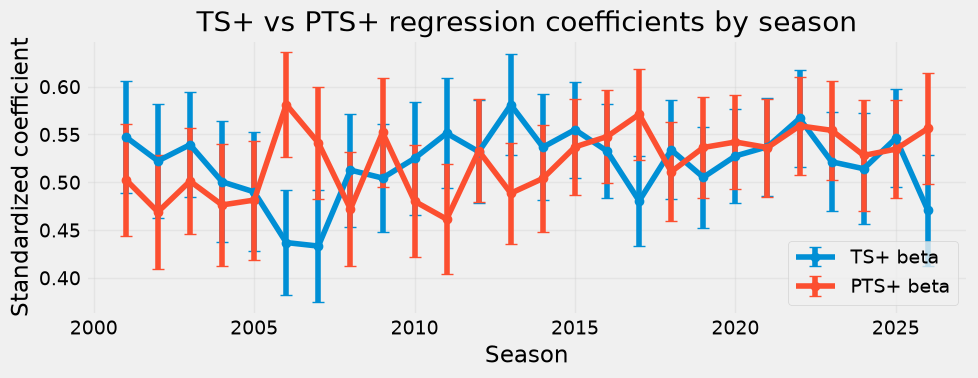

In [176]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.errorbar(
    season_betas_df['season'], season_betas_df['beta_ts'],
    yerr=season_betas_df['beta_ts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='TS+ beta'
)
ax.errorbar(
    season_betas_df['season'], season_betas_df['beta_pts'],
    yerr=season_betas_df['beta_pts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='PTS+ beta'
)

ax.set_xlabel('Season')
ax.set_ylabel('Standardized coefficient')
ax.set_title('TS+ vs PTS+ regression coefficients by season')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [177]:
season_betas_df['diff'] = season_betas_df['beta_ts'] - season_betas_df['beta_pts']
season_betas_df['diff_se'] = np.sqrt(season_betas_df['beta_ts_se']**2 + season_betas_df['beta_pts_se']**2)
season_betas_df['significant'] = season_betas_df['diff'].abs() > 1.96 * season_betas_df['diff_se']
season_betas_df

,season,n_players,beta_ts,beta_ts_se,beta_pts,beta_pts_se,diff,diff_se,significant
0,2001,178,0.547335,0.029863,0.502679,0.029863,0.044656,0.042233,False
1,2002,185,0.522286,0.030414,0.468935,0.030414,0.053351,0.043012,False
2,2003,182,0.539251,0.028172,0.501128,0.028172,0.038123,0.039841,False
3,2004,181,0.500489,0.032351,0.476236,0.032351,0.024253,0.045751,False
4,2005,187,0.489876,0.031749,0.481350,0.031749,0.008526,0.044899,False
5,2006,187,0.436881,0.027966,0.581306,0.027966,-0.144425,0.039550,True
6,2007,201,0.433217,0.030010,0.541254,0.030010,-0.108037,0.042440,True
7,2008,198,0.512696,0.030205,0.471957,0.030205,0.040739,0.042716,False
8,2009,188,0.504393,0.028922,0.552051,0.028922,-0.047658,0.040901,False
9,2010,197,0.524997,0.029983,0.480089,0.029983,0.044909,0.042403,False


In [178]:
def scoring_plus_weighting(year, df=scoring_plus_qualified_df, n_boot=1000, random_state=42):
    year_df = df[df['season_end_year'] == year]

    def compute_weights(data):
        # Fit the OLS model for ows/48
        X_ows_48 = sm.add_constant(data[['z_ts_plus', 'z_pts_plus']])
        y_ows_48 = data['z_ows_48']
        model_ows_48 = sm.OLS(y_ows_48, X_ows_48).fit()

        beta1_ows_48 = model_ows_48.params['z_ts_plus']
        beta2_ows_48 = model_ows_48.params['z_pts_plus']

        # Fit the OLS model for obpm
        X_obpm = sm.add_constant(data[['z_ts_plus', 'z_pts_plus']])
        y_obpm = data['z_obpm']
        model_obpm = sm.OLS(y_obpm, X_obpm).fit()

        beta1_obpm = model_obpm.params['z_ts_plus']
        beta2_obpm = model_obpm.params['z_pts_plus']

        # Calculate final betas
        final_beta1 = (beta1_ows_48 + beta1_obpm) / 2
        final_beta2 = (beta2_ows_48 + beta2_obpm) / 2

        # Calculate standard deviations
        sd_ts_plus = data['ts_plus'].std()
        sd_pts_plus = data['pts_plus'].std()

        # Calculate weights
        c1 = final_beta1 / sd_ts_plus
        c2 = final_beta2 / sd_pts_plus

        w1 = c1 / (c1 + c2)
        return w1, 1 - w1

    # Point estimate on the actual season data
    w1_point, w2_point = compute_weights(year_df)
    w_ts = round(w1_point, 3)
    w_pts = round(1 - w1_point, 3)

    # Bootstrap resampling for standard errors
    n = len(year_df)
    rng = np.random.default_rng(random_state)
    boot_w1 = []

    for _ in range(n_boot):
        sample = year_df.sample(n=n, replace=True, random_state=rng.integers(1_000_000))
        w1_b, _ = compute_weights(sample)
        boot_w1.append(w1_b)

    w_ts_se = np.std(boot_w1, ddof=1)

    return {
        'season': year,
        'n_players': n,
        'w_ts': w_ts,
        'w_pts': w_pts,
        'w_ts_se': w_ts_se,
        'w_pts_se': w_ts_se,  # identical to w_ts_se, since w_pts = 1 - w_ts
    }

season_weights_df = pd.DataFrame(scoring_plus_weighting(year) for year in sorted(scoring_plus_qualified_df['season_end_year'].unique()))
season_weights_df

,season,n_players,w_ts,w_pts,w_ts_se,w_pts_se
0,2001,178,0.813,0.187,0.022067,0.022067
1,2002,185,0.804,0.196,0.023474,0.023474
2,2003,182,0.805,0.195,0.018811,0.018811
3,2004,181,0.792,0.208,0.027110,0.027110
4,2005,187,0.801,0.199,0.024620,0.024620
5,2006,187,0.775,0.225,0.022074,0.022074
6,2007,201,0.749,0.251,0.027344,0.027344
7,2008,198,0.788,0.212,0.025073,0.025073
8,2009,188,0.791,0.209,0.022810,0.022810
9,2010,197,0.816,0.184,0.023582,0.023582


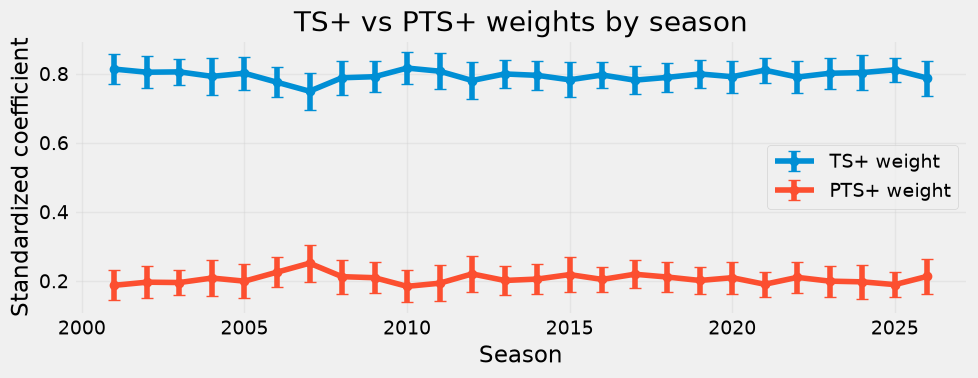

In [179]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.errorbar(
    season_weights_df['season'], season_weights_df['w_ts'],
    yerr=season_weights_df['w_ts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='TS+ weight'
)
ax.errorbar(
    season_weights_df['season'], season_weights_df['w_pts'],
    yerr=season_weights_df['w_pts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='PTS+ weight'
)

ax.set_xlabel('Season')
ax.set_ylabel('Standardized coefficient')
ax.set_title('TS+ vs PTS+ weights by season')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

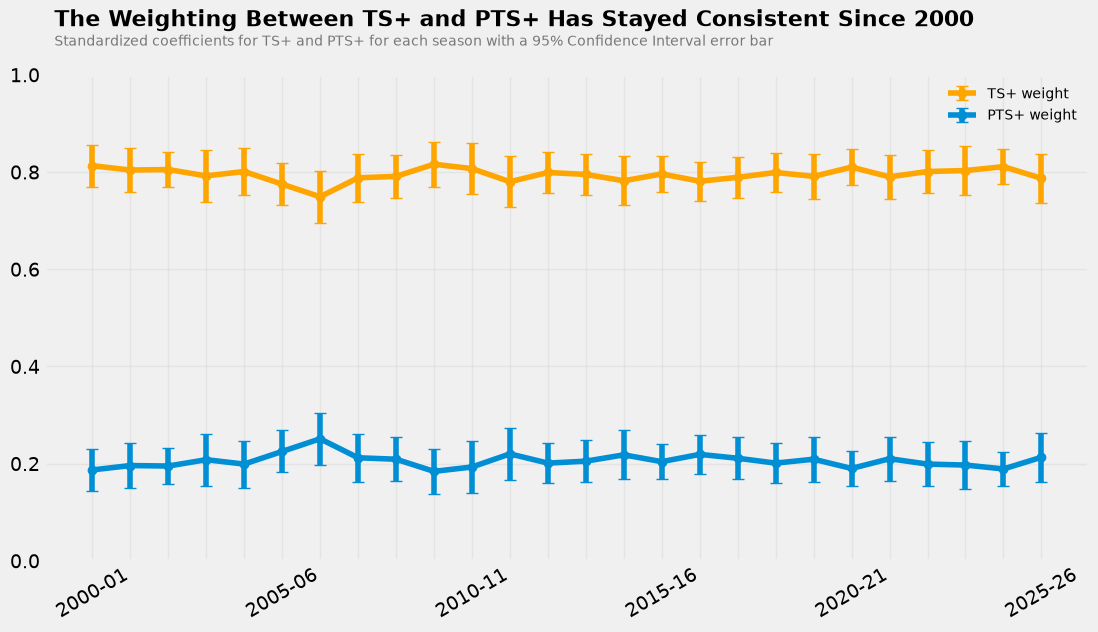

In [180]:
plt.style.use('fivethirtyeight')

fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    season_weights_df['season'], season_weights_df['w_ts'],
    yerr=season_weights_df['w_ts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='TS+ weight', color='orange'
)
ax.errorbar(
    season_weights_df['season'], season_weights_df['w_pts'],
    yerr=season_weights_df['w_pts_se'] * 1.96,  # 95% CI
    fmt='-o', capsize=4, label='PTS+ weight',
)

ax.set_xticks([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
ax.set_xticklabels(
    [
        f'{year - 1}-{year % 100:02}' if year in {2001, 2006, 2011, 2016, 2021, 2026} else ''
        for year in ax.get_xticks()
    ],
    rotation=30
)
ax.set_ylim([0,1])
ax.legend( fontsize=10, frameon=False)
ax.grid(alpha=0.3)
ax.text(2000, 1.1, 'The Weighting Between TS+ and PTS+ Has Stayed Consistent Since 2000', fontsize=16, fontweight='bold')
ax.text(2000, 1.06, 'Standardized coefficients for TS+ and PTS+ for each season with a 95% Confidence Interval error bar', fontsize=10, alpha=0.5)

plt.show()

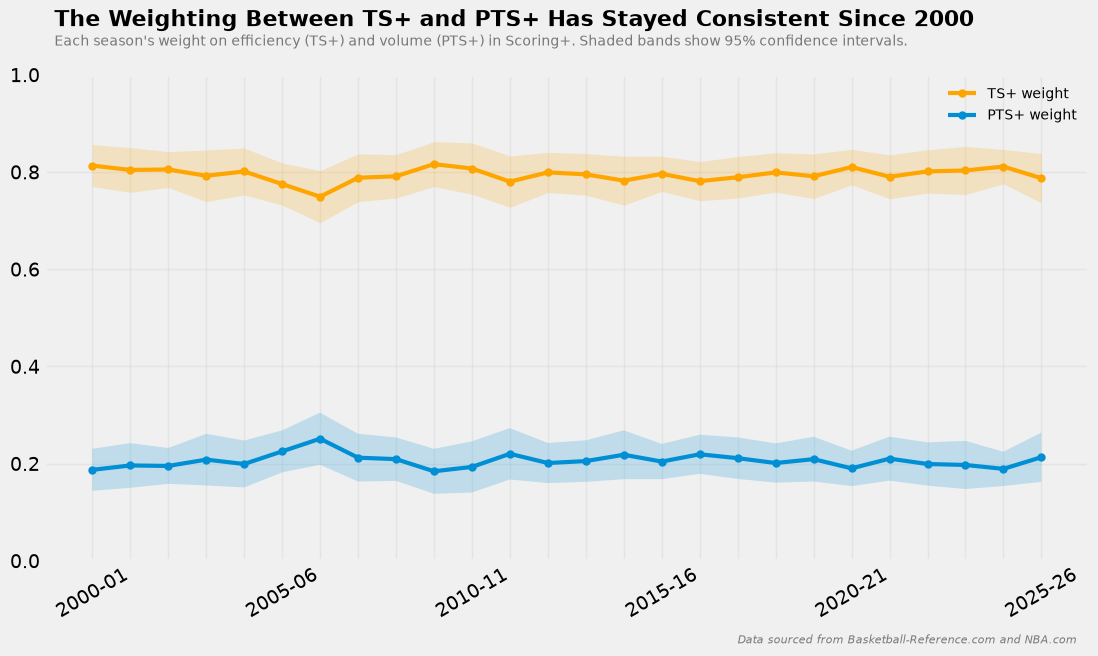

In [181]:
fig, ax = plt.subplots(figsize=(12, 6))

# TS+ weight
ci_ts = season_weights_df['w_ts_se'] * 1.96  # 95% CI

ax.plot(
    season_weights_df['season'], season_weights_df['w_ts'],
    '-o', color='orange', lw=3, markersize=5, label='TS+ weight'
)
ax.fill_between(
    season_weights_df['season'],
    season_weights_df['w_ts'] - ci_ts,
    season_weights_df['w_ts'] + ci_ts,
    color='orange', alpha=0.2, linewidth=0
)
# PTS+ weight
ci_pts = season_weights_df['w_pts_se'] * 1.96  # 95% CI

ax.plot(
    season_weights_df['season'], season_weights_df['w_pts'],
    '-o', lw=3, markersize=5, label='PTS+ weight'
)
ax.fill_between(
    season_weights_df['season'],
    season_weights_df['w_pts'] - ci_pts,
    season_weights_df['w_pts'] + ci_pts,
    alpha=0.2, linewidth=0
)

ax.set_xticks([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
ax.set_xticklabels(
    [
        f'{year - 1}-{year % 100:02}' if year in {2001, 2006, 2011, 2016, 2021, 2026} else ''
        for year in ax.get_xticks()
    ],
    rotation=30
)
ax.set_ylim([0,1])
ax.legend( fontsize=10, frameon=False)
ax.grid(alpha=0.3)
ax.text(2000, 1.1, 'The Weighting Between TS+ and PTS+ Has Stayed Consistent Since 2000', fontsize=16, fontweight='bold')
ax.text(2000, 1.06, "Each season's weight on efficiency (TS+) and volume (PTS+) in Scoring+. Shaded bands show 95% confidence intervals.", fontsize=10, alpha=0.5)
ax.text(2018, -0.17, 'Data sourced from Basketball-Reference.com and NBA.com', fontsize=8, alpha=0.5, style='italic')

plt.show()

In [182]:
overall_w_ts = 0.795  # your full-dataset result

season_weights_df['diff_from_overall'] = season_weights_df['w_ts'] - overall_w_ts
season_weights_df['significant'] = (season_weights_df['diff_from_overall'].abs() > 1.96 * season_weights_df['w_ts_se'])
season_weights_df

,season,n_players,w_ts,w_pts,w_ts_se,w_pts_se,diff_from_overall,significant
0,2001,178,0.813,0.187,0.022067,0.022067,0.018,False
1,2002,185,0.804,0.196,0.023474,0.023474,0.009,False
2,2003,182,0.805,0.195,0.018811,0.018811,0.010,False
3,2004,181,0.792,0.208,0.027110,0.027110,-0.003,False
4,2005,187,0.801,0.199,0.024620,0.024620,0.006,False
5,2006,187,0.775,0.225,0.022074,0.022074,-0.020,False
6,2007,201,0.749,0.251,0.027344,0.027344,-0.046,False
7,2008,198,0.788,0.212,0.025073,0.025073,-0.007,False
8,2009,188,0.791,0.209,0.022810,0.022810,-0.004,False
9,2010,197,0.816,0.184,0.023582,0.023582,0.021,False


In [183]:
print(sd_pts_plus)
print(sd_ts_plus)

28.583963208201723
7.350266963275837


In [184]:
print(scoring_plus_qualified_df['z_ows_48'].corr(scoring_plus_qualified_df['z_obpm']))

0.8369894628749454


In [185]:
def weights_for_targets(df, targets):
    X = sm.add_constant(df[['z_ts_plus', 'z_pts_plus']])

    beta_ts = []
    beta_pts = []
    for target in targets:
        model = sm.OLS(df[target], X).fit()
        beta_ts.append(model.params['z_ts_plus'])
        beta_pts.append(model.params['z_pts_plus'])

    final_beta_ts = sum(beta_ts) / len(beta_ts)
    final_beta_pts = sum(beta_pts) / len(beta_pts)

    c1 = final_beta_ts / df['ts_plus'].std()
    c2 = final_beta_pts / df['pts_plus'].std()

    w1 = c1 / (c1 + c2)
    return round(w1, 3), round(1 - w1, 3)

df = scoring_plus_qualified_df

print('OWS/48 only:', weights_for_targets(df, ['z_ows_48']))
print('OBPM only:  ', weights_for_targets(df, ['z_obpm']))
print('Blend:      ', weights_for_targets(df, ['z_ows_48', 'z_obpm']))

OWS/48 only: (np.float64(0.887), np.float64(0.113))
OBPM only:   (np.float64(0.661), np.float64(0.339))
Blend:       (np.float64(0.795), np.float64(0.205))
